### **Setup: Imports und Initialisierung**

In [1]:
import sys
import os
import pandas as pd

sys.path.append(os.path.abspath('..'))

from quinex_application.mongos_store import MongoStore
from quinex_application.quinex import Quinex
from quinex_application.visualisation_quinex import VisualisationQuinex
from quinex_application.oeo_data import OEOData
from quinex_application.levenshtein import LevenshteinDistance

In [2]:
quinex = Quinex()
mongodb = MongoStore(quinex, database_name="quinex_db_query2", collection_name="papers_2025")
visualisation = VisualisationQuinex()
oeo = OEOData("../data/raw/etd.xlsx", "../data/raw/oeo-full.owl", "../data/processed/oeo.xlsx")
levenshtein = LevenshteinDistance()

### **Load Analysis into DataFrame**

In [3]:
analysis = mongodb.get_collection("papers_2025")
df_path = "../data/interim/df_quinex_2025.pkl"

if os.path.exists(df_path):
    df_quinex = visualisation.load_df(df_path)
else:
    df_quinex = visualisation.create_df(analysis)
    visualisation.save_df(df_quinex, df_path)

display(df_quinex.head())

📂 Loaded DataFrame from '../data/interim/df_quinex_2025.pkl' with 64157 rows


,paper_id,entity,property,quantity,temporal_scope_text,spatial_scope_text
0,10.1038/s41597-025-04550-7,European high-voltage grid,voltage,> 200 kV,,
1,10.1038/s41597-025-04550-7,European high-voltage grid,energy system,= zero,,
2,10.1038/s41597-025-04550-7,our work,number of main advantages,= two main advantages,,
3,10.1038/s41597-025-04550-7,European,network development plan,Ten-Year,,
4,10.1038/s41597-025-04550-7,construction of the high-voltage grid,number of steps,= four steps,,


### **Metadata Results**

In [4]:
# Alle Paper-IDs, die in analysis vorkommen (mit Analyse)
analysis_ids = {paper["_id"] for paper in analysis if paper.get("analysis_result")}

# Alle Paper-IDs, die tatsächlich im DataFrame gelandet sind
df_ids = set(df_quinex["paper_id"].unique())

# Fehlende Paper mit Analyse, aber ohne quantitative Aussage
missing = analysis_ids - df_ids

print(f"🧾 Total analyzed papers (with analysis_result): {len(analysis_ids)}")
print(f"✅ Papers in DataFrame: {len(df_ids)}")
print(f"❌ Papers with no valid quantitative statements: {len(missing)}")

# Optional: welche das sind
print("Missing paper_ids:", missing)

🧾 Total analyzed papers (with analysis_result): 576
✅ Papers in DataFrame: 568
❌ Papers with no valid quantitative statements: 8
Missing paper_ids: {'10.1016/j.jestch.2025.101954', '10.1016/j.ijft.2025.101222', '10.1016/j.ref.2025.100689', '10.1016/j.ecmx.2024.100840', '10.1016/j.apenergy.2024.124648', '10.1016/j.enpol.2024.114475', '10.1016/j.ecmx.2025.100970', '10.1093/restud/rdae011'}


In [5]:
# Gesamtanzahl der quantitativen Aussagen
total_statements = len(df_quinex)

# Durchschnittliche Anzahl an Aussagen pro Paper
avg_statements_per_paper = total_statements / len(df_ids)

print(f"📊 Total quantitative statements: {total_statements}")
print(f"➗ Average statements per paper: {avg_statements_per_paper:.2f}")

📊 Total quantitative statements: 64157
➗ Average statements per paper: 112.95


### **Apply Levenshtein Method with OEO**

In [6]:
df_oeo = oeo.process_oeo_data()
display(df_oeo.head())

c:\Users\m.gorres\AppData\Local\miniforge3\envs\quinex_application_env\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,ID,LABEL,definition,URI,Super class
0,OEO:00000047,AC-line,An AC-line is a powerline for transferring high voltage alternating current.,http://openenergy-platform.org/ontology/oeo/OEO_00000047,power line
2,OEO:00010126,Annual Emission Allocation,An Annual Emission Allocation (AEA) is an emission certificate used in the Effort Sharing Decision (ESD) and the Effort Sharing Regulation (ESR). It permits the emission of a CO2 equivalent quantity of 1 tonne.,http://openenergy-platform.org/ontology/oeo/OEO_00010126,emission certificate
3,OEO:00010448,B7,B7 is a diesel fuel that consists of fossil diesel fuel and up to 7 % biodiesel and that is liquid.,http://openenergy-platform.org/ontology/oeo/OEO_00010448,diesel fuel
4,OEO:00410014,BNatSchG,The BNatSchG is a legislation providing the legal framework for nature conservation and landscape management in Germany.,http://openenergy-platform.org/ontology/oeo/OEO_00410014,None
5,OEO:00360042,BSI-KritisV energy sector,The BSI-KritisV energy sector is an energy transformation sector defined by the BSI-KritisV sector division (§ 2 BSI-KritisV).,http://openenergy-platform.org/ontology/oeo/OEO_00360042,None


In [7]:
df_path = "../data/interim/df_quinex_levenshtein_2025.pkl"

if os.path.exists(df_path):
    df_quinex = visualisation.load_df(df_path)
else:
    df_quinex[['best_oeo_match', 'match_score']] = df_quinex['entity'].apply(lambda x: pd.Series(levenshtein.get_best_match(x, df_oeo, "similarity")))
    visualisation.save_df(df_quinex, df_path)

display(df_quinex[(df_quinex['match_score'] >= 0.8) & (df_quinex['match_score'] < 1)].head(10))
print(len(df_quinex[(df_quinex['match_score'] >= 0.8) & (df_quinex['match_score'] < 1)]))

📂 Loaded DataFrame from '../data/interim/df_quinex_levenshtein_2025.pkl' with 64157 rows


,paper_id,entity,property,quantity,temporal_scope_text,spatial_scope_text,best_oeo_match,match_score
160,10.1080/15567036.2021.1922551,Biomass,potential,= 144 million tonnes per year,,Unguwar Dogo (7.4023°N 11.61172°E) located in Bakogori Local Government Area of Katsina state Nigeria,biomass,0.857143
313,10.3389/fenrg.2025.1501577,variables,value,= 0-1,,,variable,0.888889
387,10.1016/j.trpro.2025.02.025,Generator,frequency,= 60Hz,,,generator,0.888889
393,10.1016/j.trpro.2025.02.025,Fuel cell,battery SoC,= 20%,,,fuel cell,0.888889
399,10.1016/j.trpro.2025.02.025,Generator,maximum output power,= 492kW,,,generator,0.888889
400,10.1016/j.trpro.2025.02.025,Generator,load,= 100%,,,generator,0.888889
412,10.1016/j.trpro.2025.02.025,Fuel cell,Rate of the charge,~ 9% per hour,,,fuel cell,0.888889
430,10.1016/j.trpro.2025.02.025,Fuel cells,emission potential,= zero,,,fuel cell,0.800000
546,10.1016/j.trpro.2025.03.084,consumers,consumption,= 100 kW,January,,consumer,0.888889
605,10.1109/TASE.2025.3541730,tower,height,= 1 2 m,,,power,0.800000


1793


### **Visualise Results**

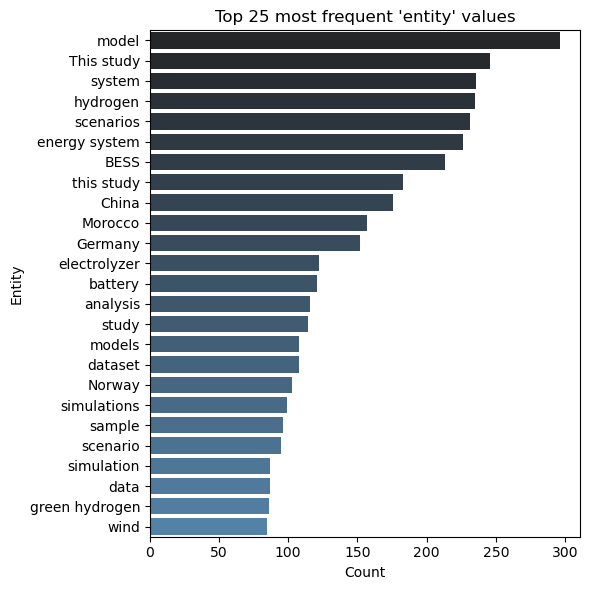

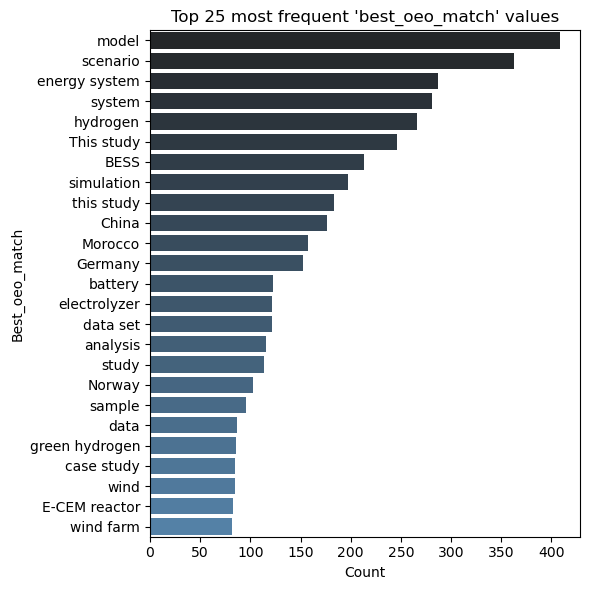

In [8]:
fig = visualisation.plot_top_values(df_quinex, column="entity", top_n=25, ignore_empty=True, figsize=(6,6))
fig = visualisation.plot_top_values(df_quinex, column="best_oeo_match", top_n=25, ignore_empty=True, figsize=(6,6))

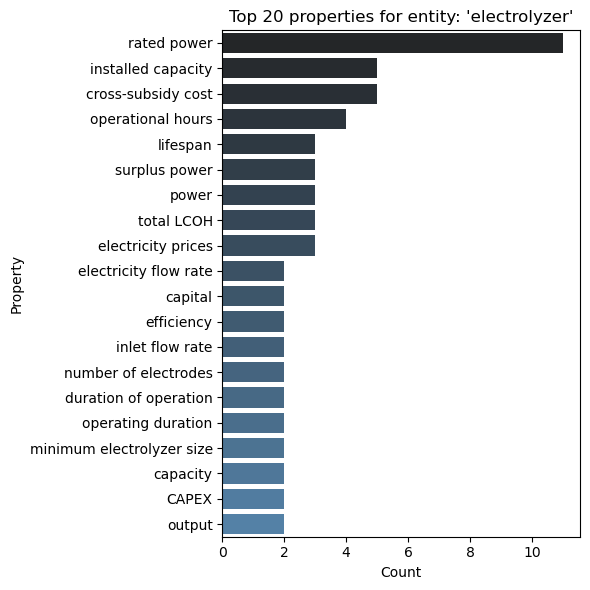

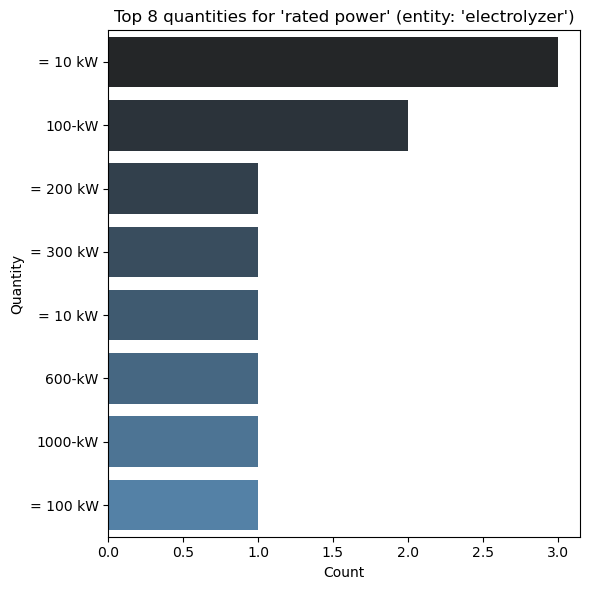

In [17]:
fig = visualisation.plot_top_properties_of_entity(df_quinex, "electrolyzer", top_n=20, ignore_empty=True, figsize=(6,6))
fig, df = visualisation.plot_top_quantity_of_property(df_quinex, "electrolyzer", "rated power", top_n=8, ignore_empty=True, figsize=(6,6))

In [10]:
display(df)

,paper_id,entity,property,quantity,temporal_scope_text,spatial_scope_text,best_oeo_match,match_score
4689,10.1016/j.ecmx.2024.100829,electrolyzer,rated power,= 10 kW,,Nigeria,electrolyzer,0.611111
8187,10.1016/j.apenergy.2024.124645,electrolyzer,rated power,= 300 kW,,,electrolyzer,0.611111
8248,10.1016/j.apenergy.2024.124645,electrolyzer,rated power,= 200 kW,,,electrolyzer,0.611111
22686,10.1016/j.gloei.2025.01.001,electrolyzer,rated power,= 10 kW,,city of Duqm in Oman,electrolyzer,0.611111
22690,10.1016/j.gloei.2025.01.001,electrolyzer,rated power,= 10 kW,,city of Duqm in Oman,electrolyzer,0.611111
22750,10.1016/j.gloei.2025.01.001,electrolyzer,rated power,= 10 kW,,Duqm,electrolyzer,0.611111
26361,10.1016/j.ijhydene.2024.05.369,electrolyzer,rated power,600-kW,,urban area,electrolyzer,0.611111
26368,10.1016/j.ijhydene.2024.05.369,electrolyzer,rated power,1000-kW,,urban area,electrolyzer,0.611111
32352,10.1016/j.rineng.2024.103674,electrolyzer,rated power,100-kW,,,electrolyzer,0.611111
32660,10.1016/j.rineng.2024.103674,electrolyzer,rated power,= 100 kW,,,electrolyzer,0.611111


In [16]:
value_counts = df["quantity"].value_counts().nlargest(10)
print(value_counts.values)
print(value_counts.index)

[3 2 1 1 1 1 1 1]
Index(['= 10 kW', '100-kW', '= 200 kW', '= 300 kW', '= 10 kW', '600-kW',
       '1000-kW', '= 100 kW'],
      dtype='object', name='quantity')
